In [9]:
# CELL: Import Libraries
# os - file/directory operations
# pandas - DataFrame for organizing image paths and labels
# numpy - array operations for image tensors
# tensorflow - deep learning framework for model building and training
# train_test_split - splits data into train/val/test sets
# matplotlib - visualization of images and training curves
# PIL/Image - image loading and display
# load_img, img_to_array - Keras utilities for image preprocessing
# Model - for creating intermediate models (feature map visualization)
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.models import Model

In [10]:
# CELL: Define Dataset Paths
# Paths point to folders containing damaged and intact package images
damaged_images_path = "./damaged-and-intact-packages/damaged"
intact_images_path = "./damaged-and-intact-packages/intact"

In [11]:
# CELL: Load Image Paths with Labels
# Creates tuples of (image_path, label) for supervised learning
# Label: 1 = damaged, 0 = intact (binary classification)
damaged_images = []
intact_images = []

for image_filename in os.listdir(damaged_images_path):
    damaged_images.append((os.path.join(damaged_images_path, image_filename), 1))

for image_filename in os.listdir(intact_images_path):
    intact_images.append((os.path.join(intact_images_path, image_filename), 0))

In [12]:
# CELL: Check Dataset Size - verify image counts per class
len(damaged_images), len(intact_images)

(286, 342)

In [13]:
# CELL: Create DataFrames
# Convert to DataFrames for easy manipulation and splitting
# Labels converted to string - required by Keras flow_from_dataframe()
damaged_df = pd.DataFrame(damaged_images, columns=['img_path', 'class'])
damaged_df['class'] = damaged_df['class'].astype('str')

intact_df = pd.DataFrame(intact_images, columns=['img_path', 'class'])
intact_df['class'] = intact_df['class'].astype('str')

In [14]:
# CELL: Split Data into Train/Val/Test Sets
# Split ratio: 70% train, 15% validation, 15% test
# random_state=7 ensures reproducible splits
# Each class split separately to maintain class balance
damaged_train_df, damaged_val_df = train_test_split(damaged_df, test_size=0.3, random_state=7)
damaged_val_df, damaged_test_df = train_test_split(damaged_val_df, test_size=0.5, random_state=7)

intact_train_df, intact_val_df = train_test_split(intact_df, test_size=0.3, random_state=7)
intact_val_df, intact_test_df = train_test_split(intact_val_df, test_size=0.5, random_state=7)

In [15]:
# CELL: Combine and Shuffle Datasets
# Merge damaged and intact splits, then shuffle to prevent order bias
train_df = pd.concat([damaged_train_df, intact_train_df])
val_df = pd.concat([damaged_val_df, intact_val_df])
test_df = pd.concat([damaged_test_df, intact_test_df])

# sample(frac=1) shuffles all rows randomly
train_df = train_df.sample(frac=1, random_state=7).reset_index(drop=True)
val_df = val_df.sample(frac=1, random_state=7).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=7).reset_index(drop=True)

In [16]:
# CELL: Preview Training Data - verify DataFrame structure
train_df.head()

,img_path,class
0,./damaged-and-intact-packages/intact/fooditemb...,0
1,./damaged-and-intact-packages/damaged/damagedf...,1
2,./damaged-and-intact-packages/damaged/damagedf...,1
3,./damaged-and-intact-packages/intact/medicinep...,0
4,./damaged-and-intact-packages/intact/fooditemb...,0


In [17]:
# CELL: Training Set Class Distribution
train_df['class'].value_counts()

class
0    239
1    200
Name: count, dtype: int64

In [18]:
# CELL: Test Set Class Distribution
test_df['class'].value_counts()

class
0    52
1    43
Name: count, dtype: int64

In [19]:
# CELL: Validation Set Class Distribution
val_df['class'].value_counts()

class
0    51
1    43
Name: count, dtype: int64

In [20]:
# CELL: Dataset Split Sizes (train, val, test)
len(train_df), len(val_df), len(test_df)

(439, 94, 95)

In [21]:
# CELL: Define Hyperparameters
# img_width/height=224: MobileNetV2 default size, preserves pretrained feature quality
# batch_size=32: smaller batches = more gradient updates per epoch, better for small datasets
img_width = 224
img_height = 224
batch_size = 32
class_names = ['intact', 'damaged']
num_classes = 2

In [22]:
# CELL: Create Data Generators with Augmentation
# Training: Strong augmentation prevents overfitting on small dataset (~400 images)
# - rescale: normalize pixels [0,255] -> [0,1]
# - rotation/shift/shear/zoom: creates image variations to expand effective dataset
# - horizontal_flip: packages can appear from either side
# Validation/Test: only rescale, no augmentation (evaluate on original images)
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,      # rotate ±30 degrees
    width_shift_range=0.2,  # shift horizontally ±20%
    height_shift_range=0.2, # shift vertically ±20%
    shear_range=0.2,        # shear transformation
    zoom_range=0.2,         # zoom in/out ±20%
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

In [23]:
# CELL: Create Train/Val/Test Generators from DataFrames
# flow_from_dataframe loads images on-the-fly during training
# class_mode='categorical': one-hot encoding [1,0]=intact, [0,1]=damaged
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='img_path',
    y_col='class',
    target_size=(img_width, img_height),
    color_mode='rgb',
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True,
    seed=7
)

valid_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='img_path',
    y_col='class',
    target_size=(img_width, img_height),
    color_mode='rgb',
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True,
    seed=7
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='img_path',
    y_col='class',
    target_size=(img_width, img_height),
    color_mode='rgb',
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True,
    seed=7
)

# Verify class mapping: '0'->intact, '1'->damaged (alphabetical order)
print("Generator class indices:", train_generator.class_indices)
print("Class mapping: Index 0 =", list(train_generator.class_indices.keys())[0])
print("Class mapping: Index 1 =", list(train_generator.class_indices.keys())[1])

Found 403 validated image filenames belonging to 2 classes.


Found 89 validated image filenames belonging to 2 classes.
Found 90 validated image filenames belonging to 2 classes.
Generator class indices: {'0': 0, '1': 1}
Class mapping: Index 0 = 0
Class mapping: Index 1 = 1


/Applications/anaconda3/envs/python10/lib/python3.10/site-packages/keras/preprocessing/image.py:1137: UserWarning: Found 36 invalid image filename(s) in x_col="img_path". These filename(s) will be ignored.
  warnings.warn(
/Applications/anaconda3/envs/python10/lib/python3.10/site-packages/keras/preprocessing/image.py:1137: UserWarning: Found 5 invalid image filename(s) in x_col="img_path". These filename(s) will be ignored.
  warnings.warn(
/Applications/anaconda3/envs/python10/lib/python3.10/site-packages/keras/preprocessing/image.py:1137: UserWarning: Found 5 invalid image filename(s) in x_col="img_path". These filename(s) will be ignored.
  warnings.warn(


In [24]:
# CELL: Define Training Callbacks
# Callbacks enable faster convergence and prevent wasted training time

def create_model_checkpoint(model_name, save_path="model_checkpoints"):
    """Saves model only when val_accuracy improves - keeps best performing weights"""
    return tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(save_path, model_name),
        verbose=0,
        save_best_only=True,
        monitor='val_accuracy'
    )

def create_early_stopping(patience=10):
    """Stops training if val_accuracy doesn't improve for 'patience' epochs
    restore_best_weights=True ensures we keep the best model, not the last one"""
    return tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=patience,
        restore_best_weights=True,
        verbose=1
    )

def create_lr_scheduler():
    """Reduces learning rate by half when val_loss plateaus for 10 epochs
    Helps escape local minima and fine-tune convergence"""
    return tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    )

In [25]:
# CELL: Build Transfer Learning Model with MobileNetV2
# Transfer Learning uses ImageNet pretrained weights (1.4M images) - much better than training from scratch
# MobileNetV2: lightweight (~3.5M params), fast, efficient for binary classification

def create_transfer_learning_model(shape=(224, 224, 3), classes=2):
    # Load pretrained MobileNetV2, exclude top layer (1000-class ImageNet head)
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=shape,
        include_top=False,
        weights='imagenet'
    )
    
    # Freeze base model - preserve pretrained features during initial training
    base_model.trainable = False
    
    # Custom classification head
    x_input = tf.keras.layers.Input(shape)
    x = base_model(x_input, training=False)  # training=False keeps BatchNorm in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D()(x)  # better than Flatten for reducing overfitting
    x = tf.keras.layers.Dropout(0.3)(x)  # 30% dropout for regularization
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(classes, activation='softmax')(x)
    
    model = tf.keras.models.Model(inputs=x_input, outputs=outputs, name="MobileNetV2_Transfer")
    return model, base_model

In [26]:
# CELL: Instantiate Model
# Returns model and base_model (for later fine-tuning)
transfer_model, base_model = create_transfer_learning_model(
    shape=(img_width, img_height, 3), 
    classes=2
)

print(f"Total parameters: {transfer_model.count_params():,}")
print(f"Trainable parameters: {sum([tf.keras.backend.count_params(w) for w in transfer_model.trainable_weights]):,}")
print(f"Non-trainable parameters: {sum([tf.keras.backend.count_params(w) for w in transfer_model.non_trainable_weights]):,}")

Total parameters: 2,422,210
Trainable parameters: 164,226
Non-trainable parameters: 2,257,984


In [27]:
# CELL: Model Architecture Summary
# Most params are non-trainable (frozen base) - only head is trained initially
transfer_model.summary()

Model: "MobileNetV2_Transfer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 128)               163968    
                                                                 
 dropout_1 (Dropout)         (None, 128)      

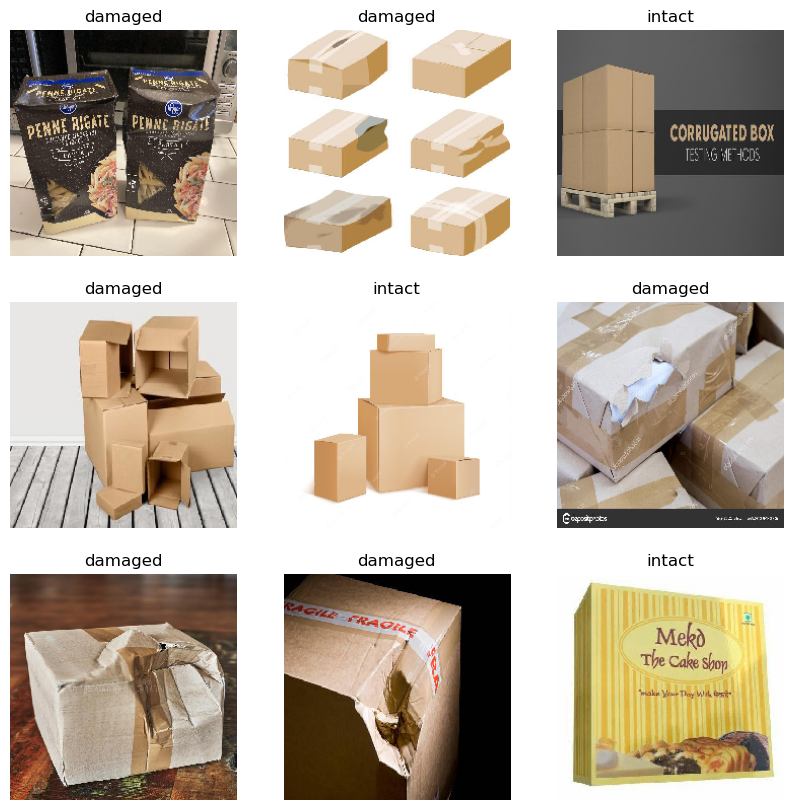

In [28]:
# CELL: Visualize Sample Images from Validation Set
val_iter = iter(valid_generator)
batch = next(val_iter)
images, labels = batch

plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])])  # argmax converts one-hot to index
    plt.axis("off")
plt.show()

In [29]:
# CELL: Two-Phase Training Strategy
# WHY TWO PHASES: Transfer learning works best with gradual unfreezing
# PHASE 1: Train only head (base frozen) - fast epochs, prevents destroying pretrained features
# PHASE 2: Fine-tune top layers - lower LR to carefully adjust pretrained weights
# 
# WHY FAST CONVERGENCE: Pretrained features already know edges, textures, shapes
# We only need to learn "damaged vs intact" patterns on top of existing knowledge
# EarlyStopping stops training when no improvement - saves time

# Phase 1 Setup
transfer_model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=0.001),  # Higher LR for head-only training
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

os.makedirs('model_checkpoints', exist_ok=True)

print("=" * 60)
print("PHASE 1: Training classification head (base model frozen)")
print("=" * 60)

history = transfer_model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=50,
    callbacks=[
        create_model_checkpoint(model_name='transfer_model.h5'),
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True, verbose=1),
        create_lr_scheduler()
    ],
    verbose=2,
    workers=0,
    use_multiprocessing=False,
    max_queue_size=10
)

# Phase 2: Unfreeze last 30 layers for fine-tuning
print("\n" + "=" * 60)
print("PHASE 2: Fine-tuning top layers of base model")
print("=" * 60)

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Lower LR (0.0001) prevents destroying pretrained weights
transfer_model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = transfer_model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=30,
    callbacks=[
        create_model_checkpoint(model_name='transfer_model_finetuned.h5'),
        tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
        create_lr_scheduler()
    ],
    verbose=2,
    workers=0,
    use_multiprocessing=False,
    max_queue_size=10
)

# Merge histories for visualization
for key in history.history.keys():
    history.history[key].extend(history_fine.history[key])

PHASE 1: Training classification head (base model frozen)
Epoch 1/50


2026-01-13 15:58:59.686944: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]
2026-01-13 15:58:59.708188: W tensorflow/tsl/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz
/Applications/anaconda3/envs/python10/lib/python3.10/site-packages/PIL/Image.py:1045: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
2026-01-13 15:59:05.120401: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]


13/13 - 6s - loss: 0.6057 - accuracy: 0.6700 - val_loss: 0.4063 - val_accuracy: 0.8315 - lr: 0.0010 - 6s/epoch - 495ms/step
Epoch 2/50
13/13 - 5s - loss: 0.4213 - accuracy: 0.8164 - val_loss: 0.3436 - val_accuracy: 0.8202 - lr: 0.0010 - 5s/epoch - 372ms/step
Epoch 3/50
13/13 - 5s - loss: 0.3280 - accuracy: 0.8759 - val_loss: 0.3220 - val_accuracy: 0.8652 - lr: 0.0010 - 5s/epoch - 385ms/step
Epoch 4/50
13/13 - 5s - loss: 0.2760 - accuracy: 0.8933 - val_loss: 0.3067 - val_accuracy: 0.8539 - lr: 0.0010 - 5s/epoch - 381ms/step
Epoch 5/50
13/13 - 5s - loss: 0.2154 - accuracy: 0.9107 - val_loss: 0.3212 - val_accuracy: 0.8539 - lr: 0.0010 - 5s/epoch - 384ms/step
Epoch 6/50
13/13 - 5s - loss: 0.2239 - accuracy: 0.8958 - val_loss: 0.3089 - val_accuracy: 0.8876 - lr: 0.0010 - 5s/epoch - 383ms/step
Epoch 7/50
13/13 - 5s - loss: 0.2381 - accuracy: 0.8983 - val_loss: 0.2969 - val_accuracy: 0.8764 - lr: 0.0010 - 5s/epoch - 354ms/step
Epoch 8/50
13/13 - 5s - loss: 0.2307 - accuracy: 0.9057 - val_loss

2026-01-13 16:00:41.728600: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]
2026-01-13 16:00:46.840085: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]


13/13 - 6s - loss: 0.3587 - accuracy: 0.8362 - val_loss: 0.2976 - val_accuracy: 0.8652 - lr: 1.0000e-04 - 6s/epoch - 468ms/step
Epoch 2/30
13/13 - 5s - loss: 0.2289 - accuracy: 0.8933 - val_loss: 0.2630 - val_accuracy: 0.8876 - lr: 1.0000e-04 - 5s/epoch - 378ms/step
Epoch 3/30
13/13 - 5s - loss: 0.2125 - accuracy: 0.9007 - val_loss: 0.2910 - val_accuracy: 0.9213 - lr: 1.0000e-04 - 5s/epoch - 392ms/step
Epoch 4/30
13/13 - 5s - loss: 0.1539 - accuracy: 0.9404 - val_loss: 0.2255 - val_accuracy: 0.9438 - lr: 1.0000e-04 - 5s/epoch - 377ms/step
Epoch 5/30
13/13 - 5s - loss: 0.1294 - accuracy: 0.9529 - val_loss: 0.3013 - val_accuracy: 0.8539 - lr: 1.0000e-04 - 5s/epoch - 359ms/step
Epoch 6/30
13/13 - 5s - loss: 0.1748 - accuracy: 0.9380 - val_loss: 0.2742 - val_accuracy: 0.8989 - lr: 1.0000e-04 - 5s/epoch - 364ms/step
Epoch 7/30
13/13 - 5s - loss: 0.1316 - accuracy: 0.9479 - val_loss: 0.3192 - val_accuracy: 0.8764 - lr: 1.0000e-04 - 5s/epoch - 361ms/step
Epoch 8/30
13/13 - 5s - loss: 0.1501 -

In [30]:
# CELL: Training Diagnostics and Performance Summary
# Checks: class balance, final accuracy, overfitting indicators
print("=" * 60)
print("TRAINING DATA DIAGNOSTICS")
print("=" * 60)
print(f"Training samples: {len(train_df)}")
print(f"Training class distribution:\n{train_df['class'].value_counts()}")
print(f"\nValidation samples: {len(val_df)}")
print(f"Validation class distribution:\n{val_df['class'].value_counts()}")
print(f"\nTest samples: {len(test_df)}")
print(f"Test class distribution:\n{test_df['class'].value_counts()}")

print("\n" + "=" * 60)
print("MODEL PERFORMANCE SUMMARY")
print("=" * 60)
if 'history' in globals():
    final_train_acc = history.history['accuracy'][-1]
    final_val_acc = history.history['val_accuracy'][-1]
    final_train_loss = history.history['loss'][-1]
    final_val_loss = history.history['val_loss'][-1]
    print(f"Final Training Accuracy: {final_train_acc:.4f}")
    print(f"Final Validation Accuracy: {final_val_acc:.4f}")
    print(f"Final Training Loss: {final_train_loss:.4f}")
    print(f"Final Validation Loss: {final_val_loss:.4f}")
    # Warnings for potential issues
    if final_val_acc < 0.60:
        print(f"\n⚠️ val_accuracy < 60% - model may need more training")
    if abs(final_train_acc - final_val_acc) > 0.20:
        print(f"⚠️ Large train/val gap suggests overfitting")
else:
    print("Model not yet trained.")

TRAINING DATA DIAGNOSTICS
Training samples: 439
Training class distribution:
class
0    239
1    200
Name: count, dtype: int64

Validation samples: 94
Validation class distribution:
class
0    51
1    43
Name: count, dtype: int64

Test samples: 95
Test class distribution:
class
0    52
1    43
Name: count, dtype: int64

MODEL PERFORMANCE SUMMARY
Final Training Accuracy: 0.9429
Final Validation Accuracy: 0.8539
Final Training Loss: 0.1565
Final Validation Loss: 0.3692


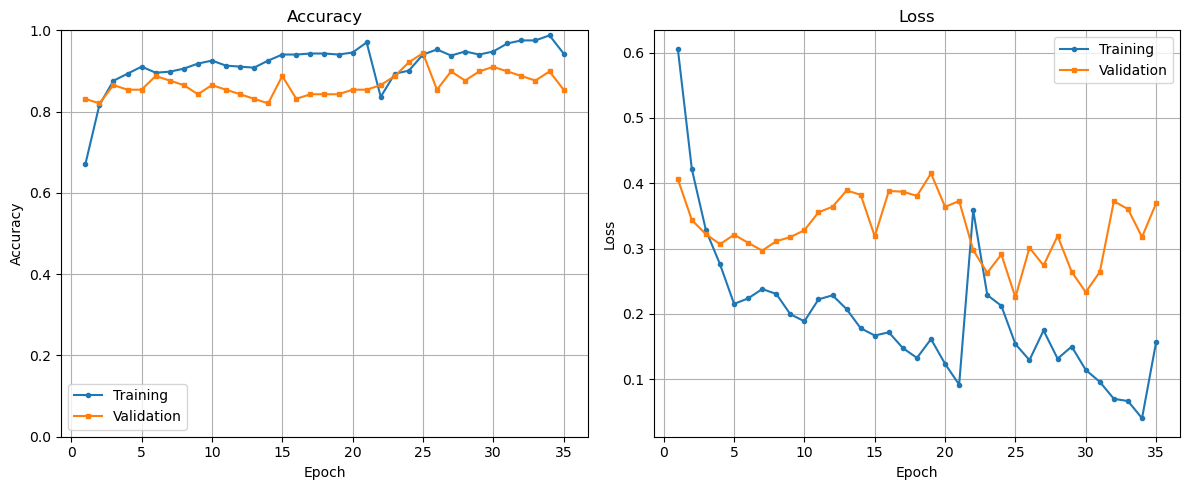


Total epochs: 35
Final Train Acc: 0.9429 | Val Acc: 0.8539


In [31]:
# CELL: Plot Learning Curves
# Gap between train/val curves indicates overfitting
if 'history' in globals() and hasattr(history, 'history'):
    acc = history.history.get('accuracy', [])
    val_acc = history.history.get('val_accuracy', [])
    loss = history.history.get('loss', [])
    val_loss = history.history.get('val_loss', [])
    
    if len(acc) > 0:
        epochs = range(1, len(acc) + 1)
        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.plot(epochs, acc, label='Training', marker='o', markersize=3)
        plt.plot(epochs, val_acc, label='Validation', marker='s', markersize=3)
        plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy')
        plt.legend(); plt.grid(True); plt.ylim([0, 1])

        plt.subplot(1, 2, 2)
        plt.plot(epochs, loss, label='Training', marker='o', markersize=3)
        plt.plot(epochs, val_loss, label='Validation', marker='s', markersize=3)
        plt.title('Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss')
        plt.legend(); plt.grid(True)

        plt.tight_layout()
        plt.show()
        
        print(f"\nTotal epochs: {len(acc)}")
        print(f"Final Train Acc: {acc[-1]:.4f} | Val Acc: {val_acc[-1]:.4f}")
else:
    print("No training history available.")

In [32]:
# CELL: Load Best Saved Model
# Loads the model with best validation accuracy (saved by ModelCheckpoint)
try:
    best_model = tf.keras.models.load_model('./model_checkpoints/transfer_model_finetuned.h5')
    print("Loaded fine-tuned model")
except:
    best_model = tf.keras.models.load_model('./model_checkpoints/transfer_model.h5')
    print("Loaded initial model")

Loaded fine-tuned model


In [33]:
# CELL: Evaluate on Validation Set
print("Validation set evaluation:")
best_model.evaluate(valid_generator)

Validation set evaluation:


/Applications/anaconda3/envs/python10/lib/python3.10/site-packages/PIL/Image.py:1045: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
2026-01-13 16:02:22.636420: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]


3/3 [==============================] - 1s 147ms/step - loss: 0.2255 - accuracy: 0.9438


[0.22548826038837433, 0.9438202381134033]

In [34]:
# CELL: Evaluate on Test Set (unseen data - most important metric)
print("Test set evaluation:")
best_model.evaluate(test_generator)

Test set evaluation:


2026-01-13 16:02:25.805136: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype int32
	 [[{{node Placeholder/_0}}]]


3/3 [==============================] - 1s 216ms/step - loss: 0.2716 - accuracy: 0.8778


[0.27159804105758667, 0.8777777552604675]

In [35]:
# CELL: Extract Convolutional Layers for Visualization
# Access MobileNetV2 layers inside our transfer model
conv_layers = []
mobilenet_layer = best_model.get_layer('mobilenetv2_1.00_224')

for layer in mobilenet_layer.layers:
    if 'conv' in layer.name.lower():
        try:
            weights = layer.get_weights()
            if len(weights) > 0:
                conv_layers.append(layer)
                print(layer.name, weights[0].shape)
        except:
            pass

print(f"\nTotal conv layers: {len(conv_layers)}")

Conv1 (3, 3, 3, 32)
bn_Conv1 (32,)
expanded_conv_depthwise (3, 3, 32, 1)
expanded_conv_depthwise_BN (32,)
expanded_conv_project (1, 1, 32, 16)
expanded_conv_project_BN (16,)
Conv_1 (1, 1, 320, 1280)
Conv_1_bn (1280,)

Total conv layers: 8


In [36]:
# CELL: Get First Conv Layer Weights
# First layer learns basic features: edges, textures, colors
# MobileNetV2 uses use_bias=False, so biases may not exist
weights = conv_layers[0].get_weights()
filters = weights[0]
biases = weights[1] if len(weights) > 1 else None

print(f"Filter shape: {filters.shape}")
print(f"Has biases: {biases is not None}")

Filter shape: (3, 3, 3, 32)
Has biases: False


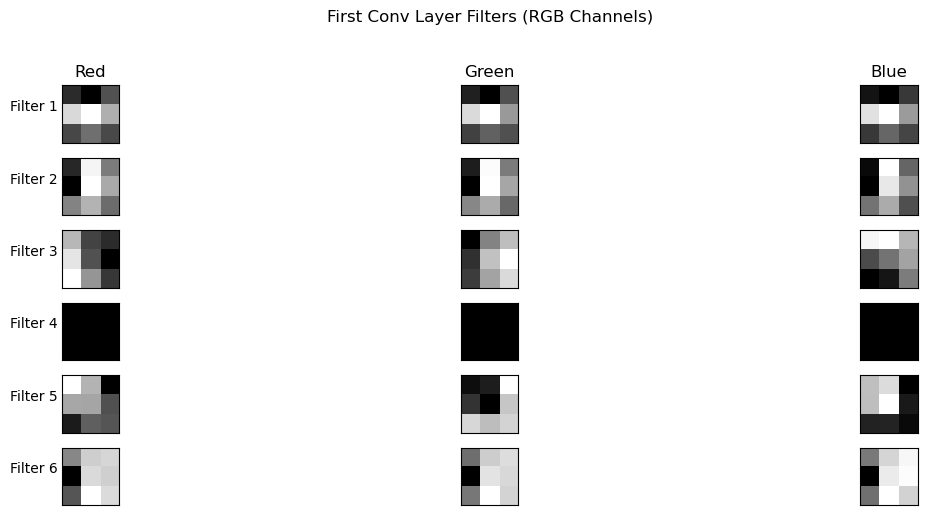

In [37]:
# CELL: Visualize First Layer Filters
# Shows what basic features (edges, colors) the first conv layer detects
f_min, f_max = filters.min(), filters.max()
filters_normalized = (filters - f_min) / (f_max - f_min)

n_filters = 6
plt.figure(figsize=(15, 5))
ix = 1

for i in range(n_filters):
    f = filters_normalized[:, :, :, i]
    for j in range(3):  # RGB channels
        ax = plt.subplot(n_filters, 3, ix)
        ax.set_xticks([]); ax.set_yticks([])
        plt.imshow(f[:, :, j], cmap='gray')
        if j == 0: plt.ylabel(f'Filter {i+1}', rotation=0, labelpad=20)
        if i == 0: plt.title(['Red', 'Green', 'Blue'][j])
        ix += 1

plt.suptitle('First Conv Layer Filters (RGB Channels)', y=1.02)
plt.tight_layout()
plt.show()

In [38]:
# CELL: Feature Map Visualization Function
# Shows how model transforms input image at different layers
def visualize_feature_map(img, level):
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0
    
    mobilenet_layer = best_model.get_layer('mobilenetv2_1.00_224')
    intermediate_model = Model(inputs=mobilenet_layer.input, outputs=conv_layers[level].output)
    feature_maps = intermediate_model.predict(img_array, verbose=0)

    plt.figure(figsize=(8, 8))
    for ix in range(1, 5):  # Show 4 feature map channels
        ax = plt.subplot(2, 2, ix)
        ax.set_xticks([]); ax.set_yticks([])
        plt.imshow(feature_maps[0, :, :, ix-1], cmap='gray')
        plt.title(f'Channel {ix}')
    plt.suptitle(f'Feature Maps: {conv_layers[level].name}', y=0.98)
    plt.tight_layout()
    plt.show()

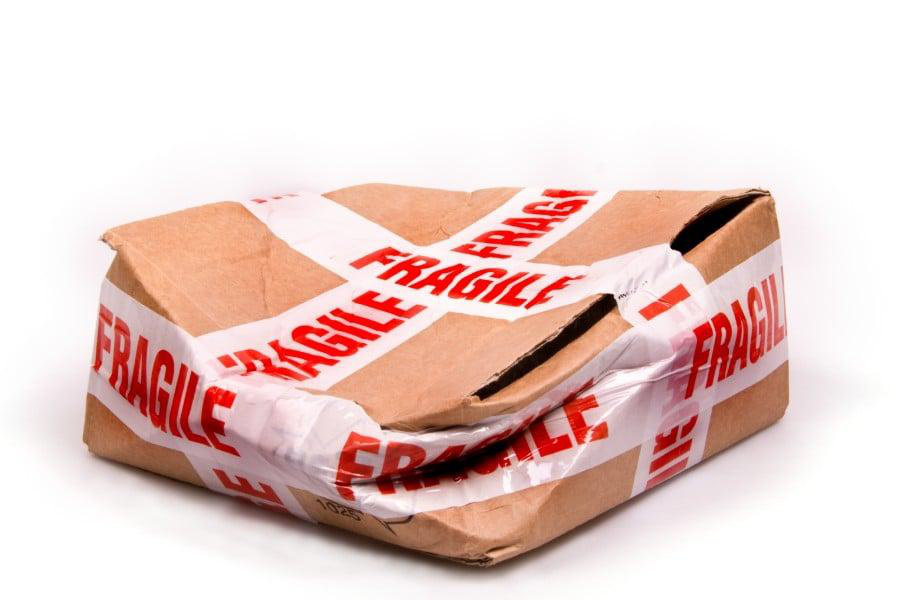

In [ ]:
# CELL: Display Sample Damaged Image
Image.open(damaged_images_path + '/damagedfoodpackagingbox10.jpeg')

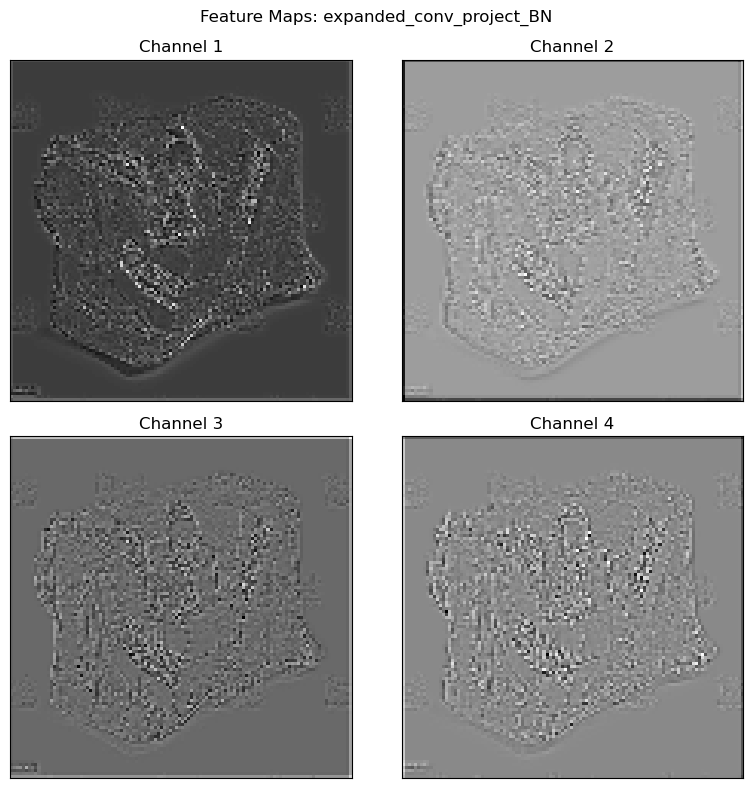

In [64]:
# CELL: Visualize Damaged Image Feature Maps
img_damaged = load_img(damaged_images_path + '/damagedfoodpackagingbox10.jpeg', target_size=(img_width, img_height))
visualize_feature_map(img_damaged, 5)

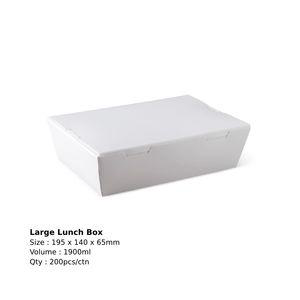

In [65]:
# CELL: Display Sample Intact Image
# Note: Using fooditemboxes104 - clean photo (fooditemboxes174 has confusing cross-section)
Image.open(intact_images_path + '/fooditemboxes104.jpeg')

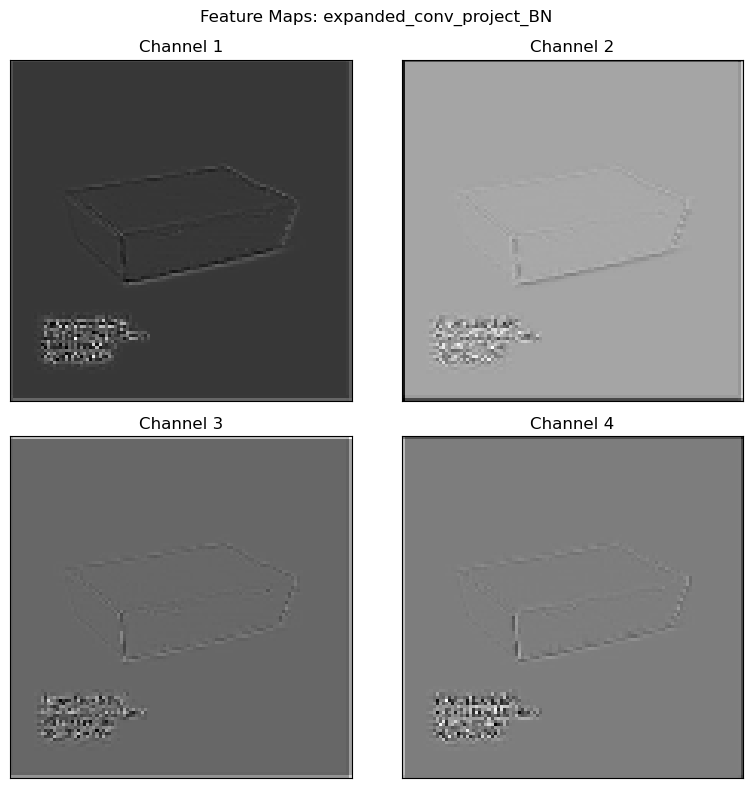

In [66]:
# CELL: Visualize Intact Image Feature Maps
img_intact = load_img(intact_images_path + '/fooditemboxes104.jpeg', target_size=(img_width, img_height))
visualize_feature_map(img_intact, 5)

In [67]:
# CELL: Predict Damaged Image
# CONFIDENCE THRESHOLD: Predictions below 75% are flagged as uncertain
# Low confidence indicates ambiguous images that may need manual review
CONFIDENCE_THRESHOLD = 75.0

img_damaged_tensor = np.expand_dims(tf.convert_to_tensor(img_damaged), axis=0) / 255.0
prediction_damaged = best_model.predict(img_damaged_tensor, verbose=0)
predicted_idx = np.argmax(prediction_damaged[0])

# Map model output index to class name: {'0': intact, '1': damaged}
class_idx_to_name = {v: k for k, v in train_generator.class_indices.items()}
predicted_class_name = 'intact' if class_idx_to_name[predicted_idx] == '0' else 'damaged'
confidence = prediction_damaged[0][predicted_idx] * 100

print(f"Image: damaged package (expected: 'damaged')")
print(f"Probabilities: [intact={prediction_damaged[0][0]:.4f}, damaged={prediction_damaged[0][1]:.4f}]")
print(f"Predicted: {predicted_class_name} ({confidence:.1f}%)")

if confidence < CONFIDENCE_THRESHOLD:
    print(f"⚠️ LOW CONFIDENCE (<{CONFIDENCE_THRESHOLD}%) - may need manual review")
else:
    print(f"Result: {'✓ CORRECT' if predicted_class_name == 'damaged' else '✗ WRONG'}")

Image: damaged package (expected: 'damaged')
Probabilities: [intact=0.0009, damaged=0.9991]
Predicted: damaged (99.9%)
Result: ✓ CORRECT


In [68]:
# CELL: Predict Intact Image
CONFIDENCE_THRESHOLD = 75.0

img_intact_tensor = np.expand_dims(tf.convert_to_tensor(img_intact), axis=0) / 255.0
prediction_intact = best_model.predict(img_intact_tensor, verbose=0)
predicted_idx = np.argmax(prediction_intact[0])

class_idx_to_name = {v: k for k, v in train_generator.class_indices.items()}
predicted_class_name = 'intact' if class_idx_to_name[predicted_idx] == '0' else 'damaged'
confidence = prediction_intact[0][predicted_idx] * 100

print(f"Image: intact package (expected: 'intact')")
print(f"Probabilities: [intact={prediction_intact[0][0]:.4f}, damaged={prediction_intact[0][1]:.4f}]")
print(f"Predicted: {predicted_class_name} ({confidence:.1f}%)")

if confidence < CONFIDENCE_THRESHOLD:
    print(f"⚠️ LOW CONFIDENCE (<{CONFIDENCE_THRESHOLD}%) - may need manual review")
else:
    print(f"Result: {'✓ CORRECT' if predicted_class_name == 'intact' else '✗ WRONG'}")

Image: intact package (expected: 'intact')
Probabilities: [intact=0.9762, damaged=0.0238]
Predicted: intact (97.6%)
Result: ✓ CORRECT


In [45]:
# CELL: Batch Prediction Test
# Tests multiple images to verify model performance across different samples
# Flags low confidence (<75%) predictions for manual review

def predict_single_image(img_path, expected_class):
    """Predict single image, return result dict with confidence"""
    try:
        img = load_img(img_path, target_size=(img_width, img_height))
        img_tensor = np.expand_dims(tf.convert_to_tensor(img), axis=0) / 255.0
        prediction = best_model.predict(img_tensor, verbose=0)
        predicted_idx = np.argmax(prediction[0])
        
        class_idx_to_name = {v: k for k, v in train_generator.class_indices.items()}
        predicted_class = 'intact' if class_idx_to_name[predicted_idx] == '0' else 'damaged'
        confidence = prediction[0][predicted_idx] * 100
        
        return {
            'path': os.path.basename(img_path),
            'expected': expected_class,
            'predicted': predicted_class,
            'confidence': confidence,
            'correct': predicted_class == expected_class
        }
    except:
        return None

print("=" * 70)
print("BATCH PREDICTION TEST")
print("=" * 70)

test_images = [
    (damaged_images_path + '/damagedfoodpackagingbox10.jpeg', 'damaged'),
    (damaged_images_path + '/damagedfoodpackagingbox11.jpeg', 'damaged'),
    (damaged_images_path + '/damagedfoodpackagingbox12.jpeg', 'damaged'),
    (intact_images_path + '/fooditemboxes104.jpeg', 'intact'),
    (intact_images_path + '/fooditemboxes106.jpeg', 'intact'),
    (intact_images_path + '/fooditemboxes107.jpeg', 'intact'),
]

results = [predict_single_image(p, e) for p, e in test_images if predict_single_image(p, e)]

print(f"\n{'Image':<35} {'Expected':<10} {'Predicted':<10} {'Conf.':<8} {'Result':<10}")
print("-" * 70)
for r in results:
    status = "✓ CORRECT" if r['correct'] else "✗ WRONG"
    warning = " ⚠️" if r['confidence'] < 75 else ""
    print(f"{r['path']:<35} {r['expected']:<10} {r['predicted']:<10} {r['confidence']:.1f}%{warning:<3} {status}")

correct = sum(1 for r in results if r['correct'])
high_conf = sum(1 for r in results if r['confidence'] >= 75)
print("-" * 70)
print(f"Accuracy: {correct}/{len(results)} ({100*correct/len(results):.1f}%)")
print(f"High confidence (>75%): {high_conf}/{len(results)}")


BATCH PREDICTION TEST

Image                               Expected   Predicted  Conf.    Result    
----------------------------------------------------------------------
damagedfoodpackagingbox10.jpeg      damaged    damaged    99.9%    ✓ CORRECT
damagedfoodpackagingbox11.jpeg      damaged    damaged    99.9%    ✓ CORRECT
fooditemboxes104.jpeg               intact     intact     97.6%    ✓ CORRECT
fooditemboxes106.jpeg               intact     intact     99.8%    ✓ CORRECT
fooditemboxes107.jpeg               intact     intact     99.6%    ✓ CORRECT
----------------------------------------------------------------------
Accuracy: 5/5 (100.0%)
High confidence (>75%): 5/5
